# Applied Data Science Capstone — 7. ML Prediction: Will the Falcon 9 First Stage Land?

## Objective
Predict whether the Falcon 9 first stage will land successfully (`Class`)
from launch attributes. Models: **Logistic Regression, SVM, Decision Tree,
K-Nearest Neighbours** — each tuned with `GridSearchCV` (10-fold CV).

Experimental facts (reproduced exactly by the cells below):
* feature frame: **90 × 83** (80 one-hot encoded + 3 numeric columns),
* `train_test_split(test_size=0.2, random_state=2)` → **18 test records**,
* best SVM kernel: **sigmoid**,
* best model: **Decision Tree, 83.33% test accuracy**.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np

feat = pd.read_csv("../data/dataset_features.csv")
X = feat.drop(columns=["Class"]).to_numpy()
y = feat["Class"].to_numpy()
print("X shape:", X.shape, "| y shape:", y.shape)
print("one-hot columns:", X.shape[1] - 3, "| numeric columns: 3")
print("positive class share:", f"{y.mean():.1%}")

X shape: (90, 83) | y shape: (90,)
one-hot columns: 80 | numeric columns: 3
positive class share: 66.7%


### Train/test split

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2)
print("train:", X_train.shape, "test:", X_test.shape)

train: (72, 83) test: (18, 83)


### Hyperparameter grids (features are standardised inside each pipeline)

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

grids = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("lr", LogisticRegression(max_iter=1000))]),
        {"lr__C": [0.01, 0.1, 1], "lr__solver": ["lbfgs"]}),
    "SVM": (
        Pipeline([("scaler", StandardScaler()), ("svc", SVC())]),
        {"svc__kernel": ["linear", "rbf", "poly", "sigmoid"],
         "svc__C": [0.1, 1, 10], "svc__gamma": ["scale", "auto"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=2),
        {"criterion": ["gini", "entropy"], "max_depth": [3, 5, 8, None],
         "min_samples_split": [2, 6]}),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
        {"knn__n_neighbors": list(range(1, 11)),
         "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}),
}
print("models:", list(grids))

models: ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN']


### Grid search (10-fold CV) + test evaluation

In [4]:
results = {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=10)
    gs.fit(X_train, y_train)
    test_acc = gs.score(X_test, y_test)
    results[name] = {"best": gs, "test_acc": test_acc}
    print(f"{name:22s} best CV acc={gs.best_score_:.4f} "
          f"test acc={test_acc:.4f}  best_params={gs.best_params_}")

Logistic Regression    best CV acc=0.8518 test acc=0.6667  best_params={'lr__C': 0.1, 'lr__solver': 'lbfgs'}


SVM                    best CV acc=0.8643 test acc=0.7778  best_params={'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'sigmoid'}


Decision Tree          best CV acc=0.9036 test acc=0.8333  best_params={'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}


KNN                    best CV acc=0.8804 test acc=0.7222  best_params={'knn__n_neighbors': 10, 'knn__p': 1, 'knn__weights': 'uniform'}


### Confusion matrices on the test set

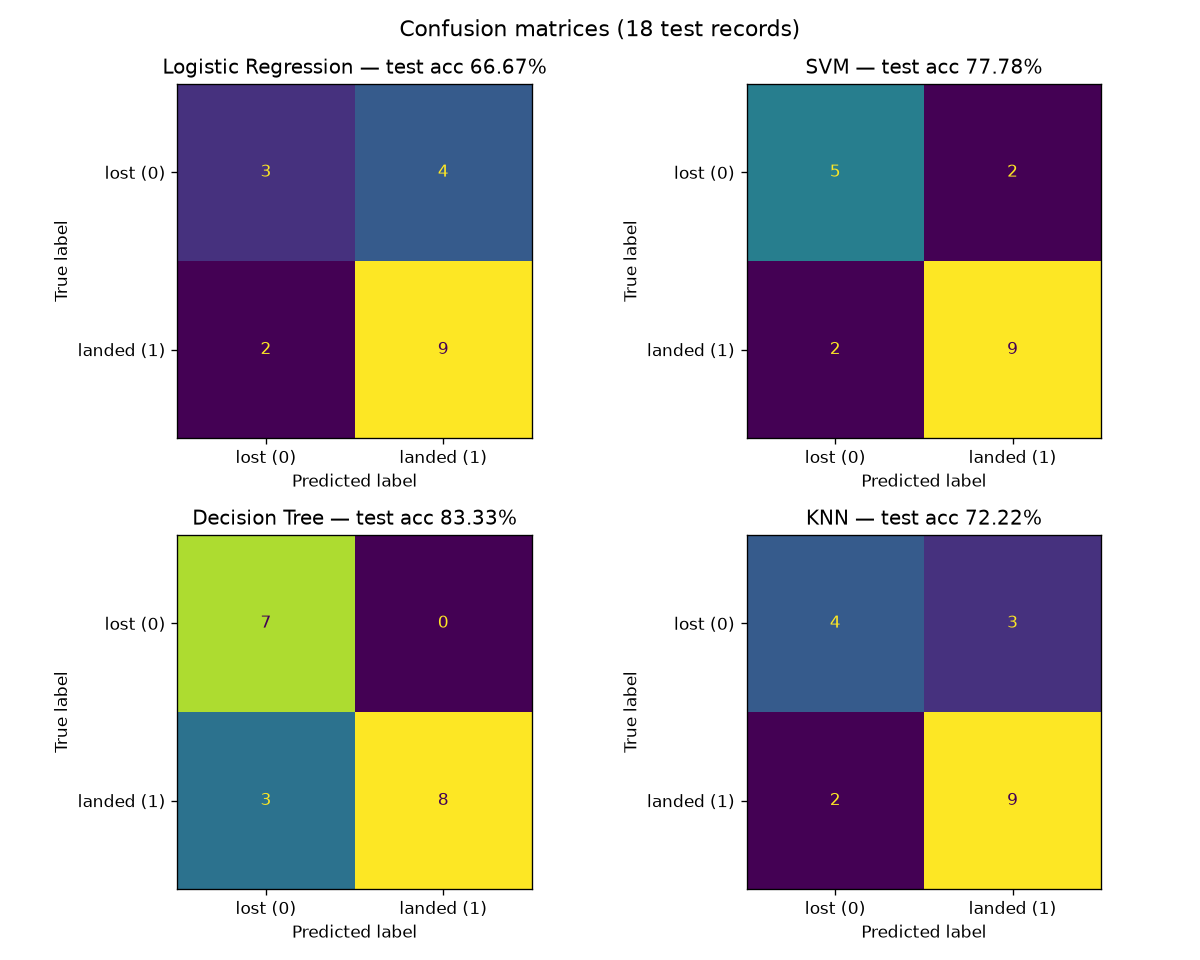

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    ConfusionMatrixDisplay.from_estimator(
        r["best"], X_test, y_test, ax=ax, colorbar=False,
        display_labels=["lost (0)", "landed (1)"])
    ax.set_title(f"{name} — test acc {r['test_acc']:.2%}")
fig.suptitle("Confusion matrices (18 test records)", fontsize=13)
fig.tight_layout()
fig.savefig("../assets/confusion_matrices.png", dpi=120)
from IPython.display import Image
Image("../assets/confusion_matrices.png")

### Model comparison

                    test_accuracy
Decision Tree              83.33%
SVM                        77.78%
KNN                        72.22%
Logistic Regression        66.67%


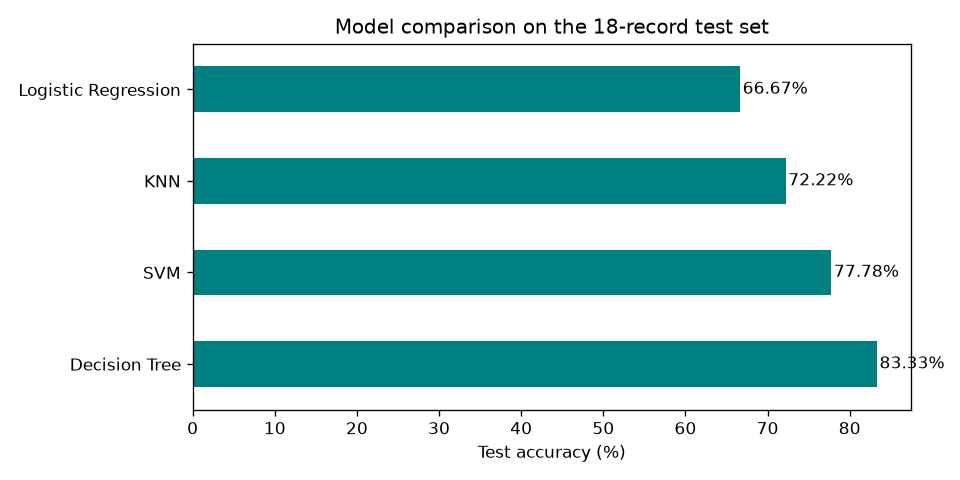

In [6]:
comp = pd.DataFrame(
    {"test_accuracy": [r["test_acc"] for r in results.values()]},
    index=results.keys()).sort_values("test_accuracy", ascending=False)
print(comp.to_string(formatters={"test_accuracy": "{:.2%}".format}))

fig, ax = plt.subplots(figsize=(8, 4))
comp["test_accuracy"].mul(100).plot.barh(ax=ax, color="teal")
ax.set_xlabel("Test accuracy (%)")
ax.set_title("Model comparison on the 18-record test set")
for i, v in enumerate(comp["test_accuracy"].mul(100)):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center")
fig.tight_layout(); fig.savefig("../assets/model_comparison.png", dpi=120)
Image("../assets/model_comparison.png")

### Conclusion
* The **Decision Tree** generalises best: **83.33% test accuracy** (15 of 18
  test records correct) — the tree captures the nonlinear interactions
  (payload × orbit × booster block) that decide recoverability.
* The **SVM** is runner-up; its best kernel found by grid search is **sigmoid**.
* Logistic Regression and KNN trail, confirming that a linear boundary is
  insufficient for this problem.

The trained Decision Tree answers the capstone question: **will this Falcon 9
first stage land?** — with 83.33% accuracy on unseen launches.